# 03 · Where is life expectancy heading? Forecasts to 2030

This notebook answers: **what can we reasonably expect life expectancy to be by 2030, and how sure can we be?**

A good forecast for public health work has four parts, and this notebook builds each one:

1. **Test before trusting.** Pretend it's 2009, 2011 or 2013, forecast forward, and compare with what actually happened (a *rolling-origin backtest*). Only models that beat simple baselines here earn a place.
2. **State the uncertainty.** Prediction intervals come from how wrong the models actually were at each horizon, not from formulas that assume the model is perfect. We then check those intervals on years they weren't built from.
3. **Separate normal uncertainty from shocks.** COVID-19 showed that the biggest risk is a shock no model can predict. Rather than pretend otherwise, we show **scenarios**.
4. **Write down every assumption** so readers can judge the forecast for themselves (section 7).

### Context
WHO warned in 2025 that progress on the health SDGs has slowed and that cuts to international aid could destabilise progress further, especially where health needs are greatest. UNICEF reports the decline in child deaths has slowed by more than 60% since 2015. So a forecast that simply extends the 2000-2015 trend is probably too optimistic, which is why the "stalled" scenario below matters.

Sources: [WHO, World Health Statistics 2025](https://www.who.int/news/item/15-05-2025-who-warns-of-slowing-global-health-gains-in-new-statistics-report) · [UNICEF, child mortality 2024](https://www.unicef.org/press-releases/progress-reducing-child-deaths-slows-49-million-children-under-five-die-2024)

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import PANEL_PATH, FIGURES_DIR, DATA_DIR
from src.plotting import set_style, REGION_COLORS, SEX_COLORS, PALETTE, INK, INK_SECONDARY, SURFACE
from src.forecasting import (series_by_country, ConvergenceModel, forecast_all, backtest, error_summary,
                             empirical_intervals, build_scenarios, METHODS)

set_style()
pd.set_option("display.width", 140, "display.precision", 2)
panel = pd.read_csv(PANEL_PATH)

FOCUS_COUNTRY = "KEN"
TARGET_YEAR = 2030

series, meta = series_by_country(panel)
years = sorted(panel.loc[panel["life_expectancy"].notna(), "year"].unique())
LAUNCH = 2019 if 2019 in years else max(y for y in years if y < 2020)
LATEST = years[-1]
H = TARGET_YEAR - LAUNCH
if (FOCUS_COUNTRY, "both") not in series:
    FOCUS_COUNTRY = next(iter(series))[0]
    print(f"Focus country not found; using {FOCUS_COUNTRY}")
REGION_ORDER = [r for r in REGION_COLORS if r in set(meta["who_region"])]

def save(fig, name):
    fig.savefig(FIGURES_DIR / f"{name}.png")

print(f"{len(series)} country-sex series. Forecasts launch from {LAUNCH} (last pre-COVID year), horizon {H} years to {TARGET_YEAR}.")
print(f"Observed data runs to {LATEST}, so {LAUNCH + 1}-{LATEST} lets us see how far COVID pushed countries off trend.")

555 country-sex series. Forecasts launch from 2019 (last pre-COVID year), horizon 11 years to 2030.
Observed data runs to 2023, so 2020-2023 lets us see how far COVID pushed countries off trend.


## 1. Backtest: which method would have forecast best?

Four methods compete:

| Method | Idea | Presumes |
|---|---|---|
| **Naive** | Next year = this year | No change at all (a floor every model must beat) |
| **Drift** | Continue the last 10 years' average gain in a straight line | Progress continues at its recent pace forever |
| **Damped** | Like drift, but each year's gain is 10% smaller than the last | Progress continues but slows |
| **Convergence** | One model learns from *all* countries how the next year's gain depends on current life expectancy, recent gains, region and sex | Countries follow the path others took at similar levels; gains slow as life expectancy rises |

Only pre-COVID years are scored, so models aren't penalised for missing a pandemic none of them could foresee.

In [2]:
ORIGINS = [LAUNCH - 10, LAUNCH - 8, LAUNCH - 6]
bt = backtest(series, meta, ORIGINS, horizon=6, last_valid_year=LAUNCH)
summary = error_summary(bt)
BEST = summary.index[0]
print(f"Backtest: {bt[['iso3','sex']].drop_duplicates().shape[0]} series, origins {ORIGINS}, {len(bt):,} scored forecasts")
print(f"Best method by mean absolute error: {BEST}")
summary

Backtest: 555 series, origins [2009, 2011, 2013], 39,960 scored forecasts
Best method by mean absolute error: damped


,MAE h=1,MAE h=2,MAE h=3,MAE h=4,MAE h=5,MAE h=6,MAE overall,bias (mean error)
method,,,,,,,,
damped,0.40,0.55,0.68,0.80,0.90,1.05,0.73,0.02
convergence,0.43,0.58,0.71,0.82,0.92,1.06,0.75,0.15
drift,0.42,0.59,0.77,0.94,1.11,1.35,0.86,0.30
naive,0.51,0.78,1.05,1.29,1.50,1.73,1.14,-0.88


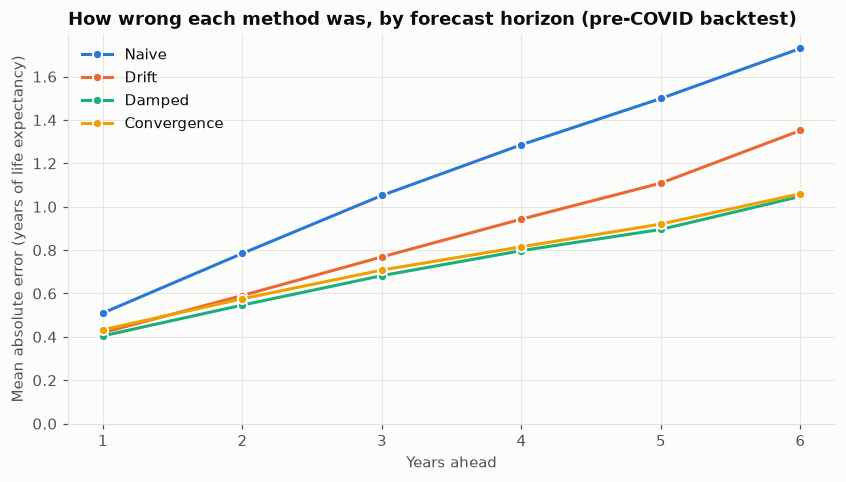

damped method, error by region (bias > 0 means forecasts were too high):


,MAE,bias
who_region,,
Africa,1.17,0.07
Americas,0.59,0.28
Eastern Mediterranean,1.25,-0.20
Europe,0.39,-0.04
South-East Asia,0.49,-0.06
Western Pacific,0.35,-0.07


In [3]:
mae_h = bt.assign(abs_err=bt["error"].abs()).groupby(["method", "h"])["abs_err"].mean().unstack(0)

fig, ax = plt.subplots(figsize=(9, 4.6))
for i, m in enumerate(METHODS):
    if m in mae_h:
        ax.plot(mae_h.index, mae_h[m], marker="o", markersize=6, color=PALETTE[i], label=m.capitalize(),
                markeredgecolor=SURFACE, markeredgewidth=1.2)
ax.set_xlabel("Years ahead")
ax.set_ylabel("Mean absolute error (years of life expectancy)")
ax.set_title("How wrong each method was, by forecast horizon (pre-COVID backtest)")
ax.set_ylim(bottom=0)
ax.legend(loc="upper left")
save(fig, "17_backtest_errors")
plt.show()

by_region = (bt[bt["method"] == BEST].merge(meta.reset_index()[["iso3", "sex", "who_region"]], on=["iso3", "sex"])
             .groupby("who_region")["error"].agg(MAE=lambda e: e.abs().mean(), bias="mean"))
print(f"{BEST} method, error by region (bias > 0 means forecasts were too high):")
by_region.reindex(REGION_ORDER)

**What to look for:** how much each method beats naive, how fast errors grow with the horizon, and whether errors are **biased** (consistently too high or too low) in some regions. Africa is usually the hardest to forecast: its gains were large and uneven (HIV treatment, malaria control), and its data are more often modelled than measured.

## 2. Prediction intervals, and do they actually work?

Intervals come from the spread of the chosen method's backtest errors at each horizon. Beyond six years ahead (the longest horizon we could test), they widen in proportion to the square root of the horizon.

To check the intervals honestly, we build them from the two earliest backtest origins and see how often the third origin's actual values fall inside them. A well-calibrated 80% interval should contain about 80% of outcomes.

In [4]:
cal = bt[bt["origin"] < ORIGINS[-1]]
test = bt[(bt["origin"] == ORIGINS[-1]) & (bt["method"] == BEST)]
iv_cal = empirical_intervals(cal, BEST, max_h=int(test["h"].max()))
t = test.join(iv_cal, on="h")
for lvl in (80, 95):
    inside = ((t["actual"] >= t["forecast"] + t[f"lo{lvl}"]) & (t["actual"] <= t["forecast"] + t[f"hi{lvl}"])).mean()
    print(f"{lvl}% interval contained {inside:.0%} of out-of-sample outcomes")

INTERVALS = empirical_intervals(bt, BEST, max_h=H)
print("\nInterval half-widths used for the final forecast (years):")
(INTERVALS[["hi80", "hi95"]] - INTERVALS[["lo80", "lo95"]].values).div(2).rename(columns={"hi80": "±80%", "hi95": "±95%"}).T.round(2)

80% interval contained 78% of out-of-sample outcomes
95% interval contained 95% of out-of-sample outcomes

Interval half-widths used for the final forecast (years):


h,1,2,3,4,5,6,7,8,9,10,11
±80%,0.35,0.56,0.73,0.91,1.08,1.31,1.41,1.51,1.60,1.69,1.77
±95%,1.01,1.35,1.88,2.14,2.41,2.79,3.01,3.22,3.42,3.60,3.78


If coverage is well below the target, the intervals are too narrow and you should say so in your write-up. Note what these intervals **don't** include: uncertainty in WHO's own estimates (shown as WHO's uncertainty bounds), and shocks like pandemics or conflict. That's what the scenarios are for.

## 3. Forecasts and scenarios to 2030

The forecast is launched from the last pre-COVID year, using the best method. Three scenarios then cover what the models can't know:

| Scenario | Presumes | Plausible when |
|---|---|---|
| **Trend (full recovery)** | Countries return to their pre-COVID path | Health systems recover and funding holds |
| **Persistent shortfall** | The gap COVID opened below the trend line is never closed; progress then continues at the trend pace | Lasting damage: long-term health effects, disrupted services, debt |
| **Stalled progress** | Gains run at half the trend pace from the launch year | Aid cuts, conflict, slowing progress against child deaths and NCDs |

In [5]:
conv_final = ConvergenceModel().fit(series, meta, last_year=LAUNCH)
fc = forecast_all(series, meta, LAUNCH, H, conv_final)
fc = fc[fc["method"] == BEST]
scen = build_scenarios(fc, series, INTERVALS, LAUNCH).merge(meta.reset_index(), on=["iso3", "sex"])

# How far off trend were countries in the latest observed year?
obs = pd.concat({k: s for k, s in series.items()}, names=["iso3", "sex", "year"]).rename("actual").reset_index()
off = scen[scen["sex"] == "both"].merge(obs, on=["iso3", "sex", "year"])
off = off[off["year"] == LATEST]
if len(off):
    gap = np.average(off["actual"] - off["trend"], weights=off["population"].fillna(off["population"].median()))
    print(f"In {LATEST}, countries were on average {gap:+.2f} years versus their pre-COVID trend (population-weighted).")
    print(f"Share of countries below trend: {(off['actual'] < off['trend']).mean():.0%}")

In 2023, countries were on average -0.70 years versus their pre-COVID trend (population-weighted).
Share of countries below trend: 66%


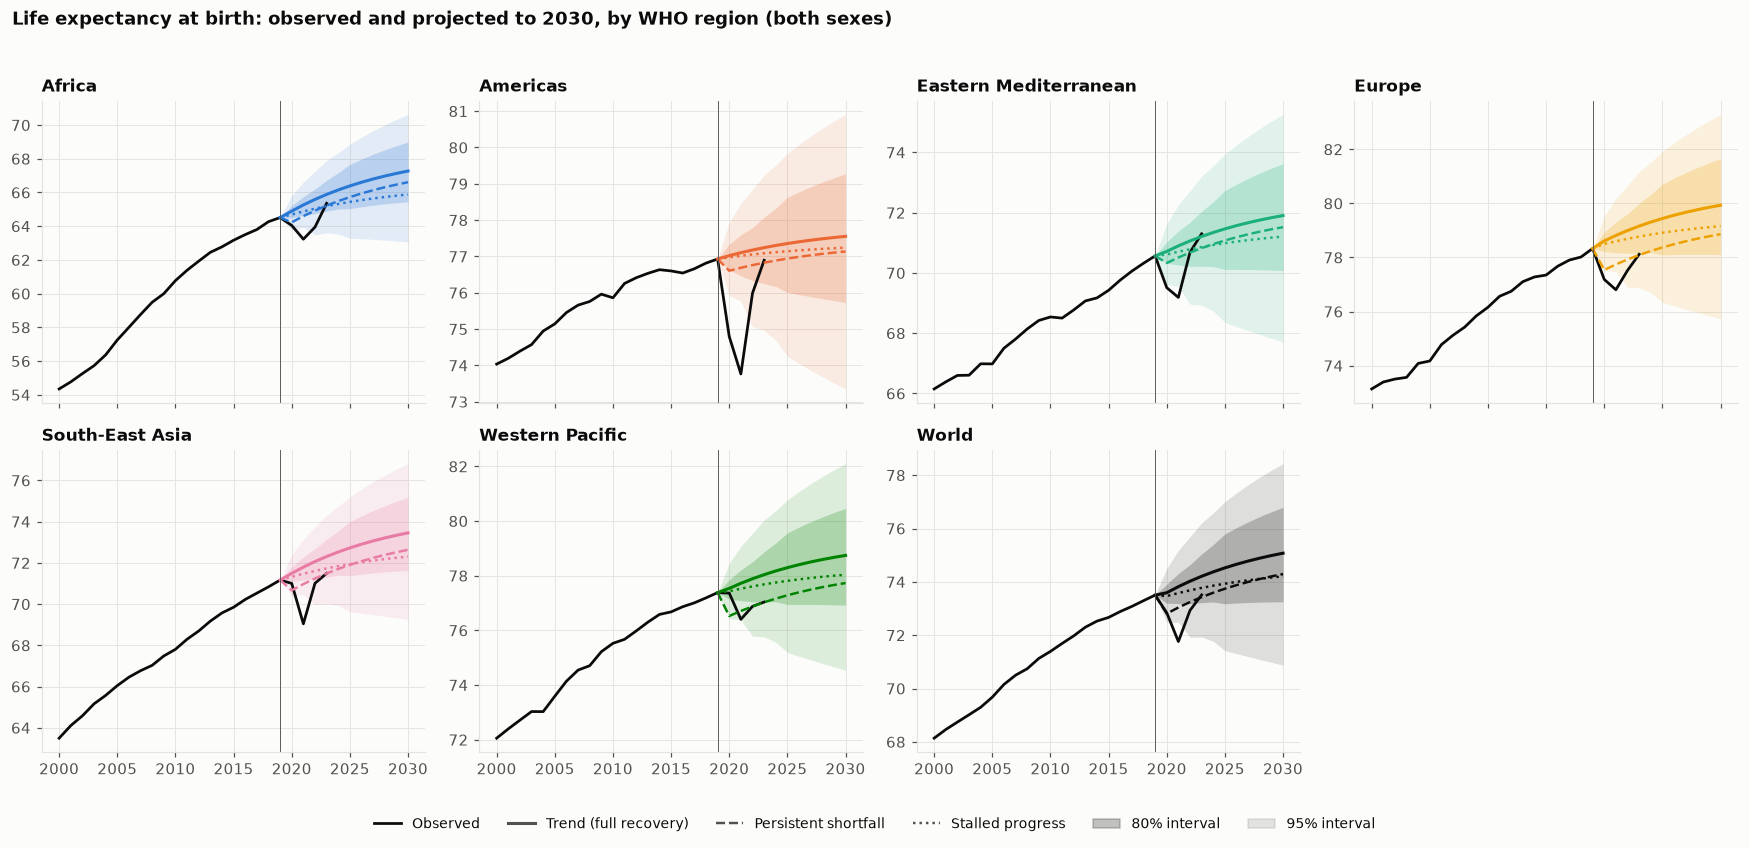

In [6]:
def weighted(df, cols):
    w = df["population"].fillna(df["population"].median())
    return pd.Series({c: np.average(df[c], weights=w) for c in cols})

COLS = ["trend", "persistent", "stalled", "lo80", "hi80", "lo95", "hi95"]
regional_fc = (scen[scen["sex"] == "both"].groupby(["who_region", "year"]).apply(lambda g: weighted(g, COLS), include_groups=False).reset_index())
world_fc = scen[scen["sex"] == "both"].groupby("year").apply(lambda g: weighted(g, COLS), include_groups=False).reset_index()
world_fc["who_region"] = "World"
regional_fc = pd.concat([regional_fc, world_fc])

hist = panel[panel["sex"] == "both"].dropna(subset=["life_expectancy"])
def hist_weighted(g):
    return np.average(g["life_expectancy"], weights=g["population"].fillna(g["population"].median()))
hist_reg = hist.groupby(["who_region", "year"]).apply(hist_weighted, include_groups=False).rename("le").reset_index()
hist_world = hist.groupby("year").apply(hist_weighted, include_groups=False).rename("le").reset_index().assign(who_region="World")
hist_reg = pd.concat([hist_reg, hist_world])

def with_launch(f, launch_value):
    # Start every scenario line and band at the observed launch-year value so it joins the history
    start = {c: launch_value for c in COLS} | {"year": LAUNCH}
    return pd.concat([pd.DataFrame([start]), f[["year"] + COLS]], ignore_index=True)

panels = REGION_ORDER + ["World"]
fig, axes = plt.subplots(int(np.ceil(len(panels) / 4)), 4, figsize=(16, 7.5), sharex=True)
for ax, region in zip(axes.flat, panels):
    h = hist_reg[hist_reg["who_region"] == region]
    f = with_launch(regional_fc[regional_fc["who_region"] == region], h.loc[h["year"] == LAUNCH, "le"].iloc[0])
    color = REGION_COLORS.get(region, INK)
    ax.fill_between(f["year"], f["lo95"], f["hi95"], color=color, alpha=0.12, linewidth=0, label="95% interval")
    ax.fill_between(f["year"], f["lo80"], f["hi80"], color=color, alpha=0.22, linewidth=0, label="80% interval")
    ax.plot(h["year"], h["le"], color=INK, linewidth=1.8, label="Observed")
    ax.plot(f["year"], f["trend"], color=color, linewidth=2, label="Trend (full recovery)")
    ax.plot(f["year"], f["persistent"], color=color, linewidth=1.6, linestyle="--", label="Persistent shortfall")
    ax.plot(f["year"], f["stalled"], color=color, linewidth=1.6, linestyle=":", label="Stalled progress")
    ax.axvline(LAUNCH, color=INK_SECONDARY, linewidth=0.6, linestyle="-")
    ax.set_title(region, fontsize=11)
for ax in list(axes.flat)[len(panels):]:
    ax.set_visible(False)
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
legend_items = [Line2D([], [], color=INK, linewidth=1.8, label="Observed"),
                Line2D([], [], color=INK_SECONDARY, linewidth=2, label="Trend (full recovery)"),
                Line2D([], [], color=INK_SECONDARY, linewidth=1.6, linestyle="--", label="Persistent shortfall"),
                Line2D([], [], color=INK_SECONDARY, linewidth=1.6, linestyle=":", label="Stalled progress"),
                Patch(color=INK_SECONDARY, alpha=0.35, label="80% interval"),
                Patch(color=INK_SECONDARY, alpha=0.15, label="95% interval")]
fig.legend(handles=legend_items, loc="lower center", ncol=6, bbox_to_anchor=(0.5, -0.03), fontsize=9)
fig.suptitle(f"Life expectancy at birth: observed and projected to {TARGET_YEAR}, by WHO region (both sexes)",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout(rect=(0, 0.03, 1, 0.96))
save(fig, "18_regional_forecasts")
plt.show()

*Regional intervals are population-weighted averages of country intervals. That assumes countries' errors move together, so regional intervals here are on the wide (cautious) side.*

In [7]:
table_2030 = regional_fc[regional_fc["year"] == TARGET_YEAR].set_index("who_region").reindex(panels)
base = hist_reg[hist_reg["year"] == LAUNCH].set_index("who_region")["le"]
summary_2030 = pd.DataFrame({
    f"{LAUNCH} observed": base,
    f"{TARGET_YEAR} trend": table_2030["trend"],
    "80% interval": table_2030["lo80"].round(1).astype(str) + " to " + table_2030["hi80"].round(1).astype(str),
    "persistent shortfall": table_2030["persistent"],
    "stalled progress": table_2030["stalled"],
    "gain if trend": table_2030["trend"] - base,
    "cost of stalling (years)": table_2030["stalled"] - table_2030["trend"],
}).reindex(panels)
summary_2030.round(1)

,2019 observed,2030 trend,80% interval,persistent shortfall,stalled progress,gain if trend,cost of stalling (years)
who_region,,,,,,,
Africa,64.5,67.3,65.5 to 69.0,66.6,65.9,2.8,-1.4
Americas,76.9,77.6,75.7 to 79.3,77.1,77.2,0.6,-0.3
Eastern Mediterranean,70.6,71.9,70.1 to 73.6,71.5,71.2,1.3,-0.7
Europe,78.3,79.9,78.1 to 81.7,78.9,79.2,1.6,-0.8
South-East Asia,71.2,73.5,71.6 to 75.2,72.6,72.3,2.3,-1.1
Western Pacific,77.4,78.7,76.9 to 80.5,77.7,78.0,1.4,-0.7
World,73.5,75.1,73.3 to 76.8,74.3,74.2,1.6,-0.9


## 4. Your focus country, by sex

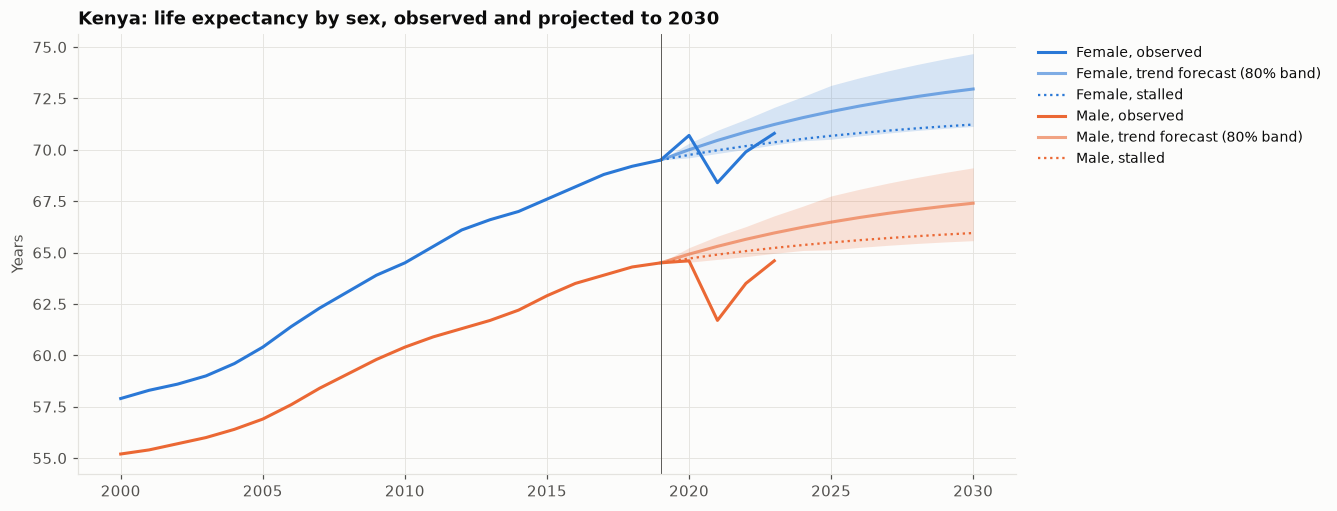

trend  lo80  hi80  persistent  stalled
sex    year                                        
both   2025   69.2  67.8  70.5        68.2     68.1
       2030   70.2  68.4  71.9        69.2     68.6
female 2025   71.9  70.5  73.1        71.4     70.7
       2030   73.0  71.1  74.7        72.5     71.2
male   2025   66.5  65.1  67.8        65.1     65.5
       2030   67.4  65.6  69.1        66.0     66.0

In [8]:
fig, ax = plt.subplots(figsize=(11, 5.2))
for sex in ["female", "male"]:
    s = series[(FOCUS_COUNTRY, sex)]
    f = with_launch(scen[(scen["iso3"] == FOCUS_COUNTRY) & (scen["sex"] == sex)], s.loc[LAUNCH])
    color = SEX_COLORS[sex]
    ax.plot(s.index, s.values, color=color, linewidth=2, label=f"{sex.capitalize()}, observed")
    ax.fill_between(f["year"], f["lo80"], f["hi80"], color=color, alpha=0.18, linewidth=0)
    ax.plot(f["year"], f["trend"], color=color, linewidth=2, linestyle="-", alpha=0.6, label=f"{sex.capitalize()}, trend forecast (80% band)")
    ax.plot(f["year"], f["stalled"], color=color, linewidth=1.5, linestyle=":", label=f"{sex.capitalize()}, stalled")
ax.axvline(LAUNCH, color=INK_SECONDARY, linewidth=0.6)
name = meta.loc[(FOCUS_COUNTRY, "both"), "country"]
ax.set_title(f"{name}: life expectancy by sex, observed and projected to {TARGET_YEAR}")
ax.set_ylabel("Years")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
save(fig, f"19_{FOCUS_COUNTRY}_forecast")
plt.show()

focus = scen[(scen["iso3"] == FOCUS_COUNTRY) & (scen["year"].isin([2025, TARGET_YEAR]))]
focus.pivot_table(index=["sex", "year"], values=["trend", "lo80", "hi80", "persistent", "stalled"]).round(1)[["trend", "lo80", "hi80", "persistent", "stalled"]]

## 5. Who is most at risk of being left behind?

In [9]:
end = scen[(scen["year"] == TARGET_YEAR) & (scen["sex"] == "both")].copy()
end["cost_of_stalling"] = end["stalled"] - end["trend"]
lowest = end.nsmallest(10, "trend")[["country", "who_region", "trend", "lo80", "hi80", "stalled"]]
print(f"Lowest projected life expectancy in {TARGET_YEAR} (trend scenario):")
print(lowest.round(1).to_string(index=False))

most_exposed = end.nsmallest(10, "cost_of_stalling")[["country", "who_region", "trend", "stalled", "cost_of_stalling"]]
print(f"\nWhere stalled progress would cost the most years by {TARGET_YEAR}:")
print(most_exposed.round(1).to_string(index=False))

Lowest projected life expectancy in 2030 (trend scenario):
                 country            who_region  trend  lo80  hi80  stalled
Central African Republic                Africa   52.5  50.7  54.2     47.4
                 Lesotho                Africa   55.8  54.0  57.5     54.5
      Somalia, Fed. Rep. Eastern Mediterranean   58.1  56.3  59.9     56.7
             South Sudan                Africa   60.5  58.7  62.2     60.1
                   Niger                Africa   61.7  59.9  63.5     61.0
                    Chad                Africa   62.0  60.2  63.8     60.8
              Mozambique                Africa   62.2  60.4  64.0     60.8
           Guinea-Bissau                Africa   62.3  60.5  64.0     61.0
                Kiribati       Western Pacific   62.7  60.9  64.5     62.5
                  Guinea                Africa   63.1  61.3  64.8     62.1

Where stalled progress would cost the most years by 2030:
                 country who_region  trend  stalled  cost

These two lists overlap a lot: the countries with the lowest life expectancy are also the ones with the fastest expected gains, so they have the most to lose if progress stalls. That's the core equity argument for sustaining funding where needs are greatest, and a strong point for a policy brief.

## 6. Compare with official UN projections (optional, recommended)

Comparing with the **UN World Population Prospects (WPP)** is what a reviewer will ask about first. To add it:

1. Download the WPP life expectancy file (CSV) from the UN Population Division data portal.
2. Reshape it to columns `iso3, year, sex, wpp_le` (sex as `both`/`female`/`male`) and save it as `data/external/wpp_life_expectancy.csv`.
3. Re-run this cell.

Where your forecast and the UN's differ by more than a year or two, investigate why: different data, different handling of COVID, or different assumptions about the pace of progress.

In [10]:
wpp_path = DATA_DIR / "external" / "wpp_life_expectancy.csv"
if wpp_path.exists():
    wpp = pd.read_csv(wpp_path)
    cmp_ = scen.merge(wpp, on=["iso3", "year", "sex"])
    cmp_ = cmp_[cmp_["year"] == TARGET_YEAR]
    cmp_["ours_minus_un"] = cmp_["trend"] - cmp_["wpp_le"]
    print(f"Countries compared: {cmp_['iso3'].nunique()}. Mean difference (ours - UN) in {TARGET_YEAR}: {cmp_['ours_minus_un'].mean():+.2f} years")
    print(cmp_.groupby("who_region")["ours_minus_un"].describe()[["mean", "min", "max"]].round(2))
else:
    print(f"No UN WPP file at {wpp_path.relative_to(ROOT)}; see the instructions above.")

No UN WPP file at data\external\wpp_life_expectancy.csv; see the instructions above.


## 7. What these forecasts presume

Write these assumptions into your README and policy brief. Being explicit about them is a mark of serious forecasting work.

1. **The past is a guide.** Countries continue on the path they (and similar countries) were on before 2020. Nothing in the model knows about new vaccines, treatments, wars or funding decisions.
2. **COVID-19 is treated as a shock, not a new trend.** The models learn only from pre-2020 years; the scenarios bound what happened next.
3. **WHO's estimates are taken as the truth.** For many low-income countries, life expectancy is itself modelled from incomplete death registration, so the "observed" history carries uncertainty our intervals don't include.
4. **Countries are independent.** Regional aggregates assume populations stay at their latest size and that countries don't influence each other.
5. **The intervals cover normal year-to-year forecast error only**, as measured in 2009-2019. Major shocks sit outside them.

## 8. Summary (generated from your data)

In [11]:
w = summary_2030.loc["World"]
print(f"- Best method in backtesting: {BEST} (mean absolute error {summary.loc[BEST, 'MAE overall']:.2f} years vs "
      f"{summary.loc['naive', 'MAE overall']:.2f} for the naive forecast).")
print(f"- World life expectancy: {w[f'{LAUNCH} observed']:.1f} in {LAUNCH}; projected {w[f'{TARGET_YEAR} trend']:.1f} in {TARGET_YEAR} "
      f"if pre-COVID progress resumes (80% interval {w['80% interval']}).")
print(f"- If progress stalls at half pace, world life expectancy in {TARGET_YEAR} would be {w['stalled progress']:.1f}, "
      f"{abs(w['cost of stalling (years)']):.1f} years lower than the trend.")
reg = summary_2030.drop("World")
print(f"- Largest projected gain: {reg['gain if trend'].idxmax()} ({reg['gain if trend'].max():+.1f} years); "
      f"most exposed to stalling: {reg['cost of stalling (years)'].idxmin()} ({reg['cost of stalling (years)'].min():.1f} years).")

- Best method in backtesting: damped (mean absolute error 0.73 years vs 1.14 for the naive forecast).
- World life expectancy: 73.5 in 2019; projected 75.1 in 2030 if pre-COVID progress resumes (80% interval 73.3 to 76.8).
- If progress stalls at half pace, world life expectancy in 2030 would be 74.2, 0.9 years lower than the trend.
- Largest projected gain: Africa (+2.8 years); most exposed to stalling: Africa (-1.4 years).
